# 08 — Corrected SMAP gap-filling machine-learning experiments

**Research question:** Do models trained on independent **past** observations reconstruct *held-out QA-accepted SMAP AM product values* better than simple training-only baselines?

- One observation per **SMAP grid posting × observation date**; no assigning the same district-mean SMAP target to hundreds of high-resolution pixels.
- Chronological train/validation/test periods (2019–20 / 2021 / 2022 by default), strict time boundaries. **Test is never used for model selection or early stopping.**
- Compare global-mean and calendar-month climatology baselines with Ridge, Random Forest and XGBoost (if installed), across climate+terrain, +radar, +vegetation and +both groups.
- Time-date-balanced sample weights and errors limit domination by days with more QA-accepted postings. Date-block bootstrap interval describes **sampling variation of satellite-product error**, not physical uncertainty.
- Independent spatial-grid holdout is attempted **only if enough observed grids and dates exist**.

**No ground truth**. Success here supports *SMAP-product reconstruction*, not absolute volumetric soil-moisture accuracy, 9-km independent footprint accuracy or causation. If data are too sparse, the notebook **stops before fitting**, reporting feasibility.


## 1. Import strict, QA-checked Notebook 07 data

Required local file: `data/processed/07_smap_ml_table.csv`, created from **real** Drive CSVs by Notebook 07. Pilot 2021 Q1 is intentionally insufficient for a 2019–2022 independent test. Export more quarters/years before running this notebook; no fake data or target interpolation will be generated.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

try:
    import xgboost as xgb
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False
    xgb = None
    print('XGBoost is not installed; install with python -m pip install xgboost')

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'configs' / 'study_config.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from the project root or notebooks/.')
DATA_FILE = ROOT / 'data' / 'processed' / '07_smap_ml_table.csv'
if not DATA_FILE.is_file():
    raise FileNotFoundError(f'Notebook 07 must produce REAL QA-checked data first: {DATA_FILE}')
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
CFG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
df = pd.read_csv(DATA_FILE, parse_dates=['date'])

# Edit these ONLY before evaluation, never in response to test performance.
TRAIN_START, TRAIN_END = '2019-01-01', '2021-01-01'
VAL_START, VAL_END = '2021-01-01', '2022-01-01'
TEST_START, TEST_END = '2022-01-01', '2023-01-01'
MIN_ROWS = {'train': 100, 'validation': 40, 'test': 40}
MIN_DATES = {'train': 30, 'validation': 15, 'test': 15}
MIN_GRIDS_EACH = 5
RANDOM_SEED = 2026

TARGET = 'smap_sm_m3m3'
CORE = ['rain_prior1_mm', 'rain_prior7_mm', 'elevation_m', 'slope_deg', 'doy_sin', 'doy_cos']
RADAR = ['s1_vv_db', 's1_vh_db', 's1_vh_minus_vv_db']
VEGETATION = ['evi_strict_qa']
GROUPS = {
    'climate_terrain_calendar': CORE,
    'plus_radar': CORE + RADAR,
    'plus_vegetation': CORE + VEGETATION,
    'plus_radar_and_vegetation': CORE + RADAR + VEGETATION,
}

needed = {'date','district','grid_id','retrieval_qual_flag_am', 'target_qa_valid', TARGET}
needed |= set(CORE[:-2] + RADAR + VEGETATION)
missing = needed - set(df.columns)
if missing:
    raise ValueError(f'Missing Notebook 07 fields: {sorted(missing)}')
assert not df.duplicated(['grid_id', 'date']).any(), 'Duplicate SMAP grid × date rows.'
assert not df.date.isna().any(), 'Invalid/blank dates.'
assert df.district.isin(CFG['expected_districts']).all()
if df.target_qa_valid.dtype != bool:
    df['target_qa_valid'] = df['target_qa_valid'].astype(str).str.lower().eq('true')
assert df.loc[df.target_qa_valid, 'retrieval_qual_flag_am'].eq(0).all()
assert df.loc[df.target_qa_valid, TARGET].between(0, 1).all()
assert df.loc[~df.target_qa_valid, TARGET].isna().all(), 'Unaccepted targets must be blank.'

day_of_year = df.date.dt.dayofyear
df['doy_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
df['doy_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)
df['calendar_month'] = df.date.dt.month
valid = df[df.target_qa_valid].copy()
print('Loaded rows:', len(df), '| QA-accepted target rows:', len(valid),
      '| accepted dates:', valid.date.nunique(), '| observed grids:', valid.grid_id.nunique())
print('Input SHA256:', hashlib.sha256(DATA_FILE.read_bytes()).hexdigest())


Loaded rows: 248400 | QA-accepted target rows: 17653 | accepted dates: 663 | observed grids: 39
Input SHA256: d97e6e3a8b794a7155182df2541d7cc84a5c905b4b8aa45cd1e70ba8a85fe0d6


C:\Users\HP\AppData\Local\Temp\ipykernel_8044\3744632144.py:69: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  day_of_year = df.date.dt.dayofyear


## 2. A hard feasibility gate **before** training

The minimum sizes below are **pragmatic, exploratory safeguards**, not statistical power calculations. Distinct *dates* and *grids* matter more than the total pixel-date count; no significance claims are made. Edit only with a written rationale. We make no model fit if any period fails.


In [2]:
def in_period(table, start, end):
    return table[(table.date >= pd.Timestamp(start)) & (table.date < pd.Timestamp(end))].copy()

train = in_period(valid, TRAIN_START, TRAIN_END)
val = in_period(valid, VAL_START, VAL_END)
test = in_period(valid, TEST_START, TEST_END)
assert pd.Timestamp(TRAIN_END) <= pd.Timestamp(VAL_START)
assert pd.Timestamp(VAL_END) <= pd.Timestamp(TEST_START)
assert pd.Timestamp(TRAIN_START) < pd.Timestamp(TRAIN_END)
assert pd.Timestamp(VAL_START) < pd.Timestamp(VAL_END)
assert pd.Timestamp(TEST_START) < pd.Timestamp(TEST_END)

splits = {'train': train, 'validation': val, 'test': test}
support = pd.DataFrame([{'period': name, 'accepted_rows': len(part),
                         'dates': part.date.nunique(), 'grids': part.grid_id.nunique(),
                         'first_date': part.date.min(), 'last_date': part.date.max()}
                        for name, part in splits.items()])
display(support)
failed = []
for name, part in splits.items():
    if len(part) < MIN_ROWS[name]:
        failed.append(f'{name}: {len(part)} accepted rows < {MIN_ROWS[name]}')
    if part.date.nunique() < MIN_DATES[name]:
        failed.append(f'{name}: {part.date.nunique()} observed dates < {MIN_DATES[name]}')
    if part.grid_id.nunique() < MIN_GRIDS_EACH:
        failed.append(f'{name}: {part.grid_id.nunique()} observed grids < {MIN_GRIDS_EACH}')

TABLES.mkdir(parents=True, exist_ok=True)
support.to_csv(TABLES / '08_split_feasibility.csv', index=False)
if failed:
    report = {'status': 'blocked_insufficient_qa_accepted_smap',
              'issues': failed, 'input_sha256': hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
              'created_utc': datetime.now(timezone.utc).isoformat()}
    (TABLES / '08_model_run_manifest.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
    raise RuntimeError('STOP: insufficient QA-accepted temporal test support.\n'
                       + '\n'.join(failed)
                       + '\nExport more quarters/years in Notebook 07; never report fictitious test metrics.')

print('Feasibility gate passed. All later reported scores are satellite-product errors only.')


,period,accepted_rows,dates,grids,first_date,last_date
0,train,9084,348,39,2019-01-01,2020-12-30
1,validation,4527,172,39,2021-01-03,2021-12-30
2,test,4042,143,39,2022-01-01,2022-12-30


Feasibility gate passed. All later reported scores are satellite-product errors only.


## 3. Fair date-balanced metrics and baselines

For evaluation, weight each observation by the inverse of the number of accepted grid postings **on its date**, so every date contributes equal total weight. This does **not** eliminate time/spatial dependence. Baseline climatology is derived only from the **training** period; unknown months revert to its overall mean.


In [3]:
def date_weights(part):
    return (1.0 / part.groupby('date')['date'].transform('size')).to_numpy(dtype=float)

def metrics(part, predictions):
    y = part[TARGET].to_numpy(dtype=float)
    pred = np.asarray(predictions, dtype=float)
    assert len(y) == len(pred) and np.isfinite(pred).all()
    w = date_weights(part)
    err = pred - y
    mu = np.average(y, weights=w)
    ss_total = np.sum(w * (y - mu)**2)
    return {'RMSE': float(np.sqrt(np.average(err**2, weights=w))),
            'MAE': float(np.average(np.abs(err), weights=w)),
            'bias': float(np.average(err, weights=w)),
            'R2': float(1 - np.sum(w * err**2) / ss_total) if ss_total > 0 else np.nan,
            'n_rows': int(len(part)), 'n_dates': int(part.date.nunique()),
            'n_grids': int(part.grid_id.nunique())}

def baseline_predictions(fit_part, eval_part, baseline):
    mean = float(np.average(fit_part[TARGET], weights=date_weights(fit_part)))
    if baseline == 'global_mean':
        return np.full(len(eval_part), mean, dtype=float)
    if baseline == 'calendar_month':
        monthly = {m: float(np.average(g[TARGET], weights=date_weights(g)))
                   for m, g in fit_part.groupby('calendar_month')}
        return eval_part.calendar_month.map(monthly).fillna(mean).to_numpy(dtype=float)
    raise ValueError(baseline)

def estimator(algorithm):
    if algorithm == 'Ridge':
        base = Ridge(alpha=10.0)
        return make_pipeline(SimpleImputer(strategy='median', add_indicator=True,
                                           keep_empty_features=True), StandardScaler(), base)
    if algorithm == 'RandomForest':
        return make_pipeline(SimpleImputer(strategy='median', add_indicator=True,
                                           keep_empty_features=True),
                             RandomForestRegressor(n_estimators=250, min_samples_leaf=5,
                                                   max_features=0.8, random_state=RANDOM_SEED,
                                                   n_jobs=-1))
    if algorithm == 'XGBoost' and XGB_AVAILABLE:
        return make_pipeline(SimpleImputer(strategy='median', add_indicator=True,
                                           keep_empty_features=True),
                             xgb.XGBRegressor(n_estimators=250, max_depth=3,
                                              learning_rate=0.04, subsample=0.8,
                                              colsample_bytree=0.85, objective='reg:squarederror',
                                              random_state=RANDOM_SEED, n_jobs=4))
    raise ValueError(f'Algorithm not installed: {algorithm}')

ALGORITHMS = ['Ridge', 'RandomForest'] + (['XGBoost'] if XGB_AVAILABLE else [])
print('Candidate models:', ALGORITHMS)
print('No early stopping or tuning uses the test period.')


Candidate models: ['Ridge', 'RandomForest', 'XGBoost']
No early stopping or tuning uses the test period.


## 4. Fixed candidate comparisons on validation only

Every model is trained on the **same QA-accepted dates** and scored on the same validation dates. Scikit-learn imputers learn medians only from training rows; missingness indicators are added as features. Scores are not interpreted as physical accuracy. We select a single configuration from validation RMSE before opening the independent test.


In [4]:
candidate_results = []
for group_name, features in GROUPS.items():
    for algorithm in ALGORITHMS:
        model = estimator(algorithm)
        model.fit(train[features], train[TARGET],
                  **{f'{model.steps[-1][0]}__sample_weight': date_weights(train)})
        predicted = model.predict(val[features])
        result = metrics(val, predicted)
        candidate_results.append({'feature_group': group_name, 'model': algorithm, **result})

for baseline in ('global_mean', 'calendar_month'):
    result = metrics(val, baseline_predictions(train, val, baseline))
    candidate_results.append({'feature_group': 'train_only', 'model': baseline, **result})

validation_scores = pd.DataFrame(candidate_results).sort_values(['RMSE', 'model'])
display(validation_scores.round(5))
model_candidates = validation_scores[validation_scores.model.isin(ALGORITHMS)]
best = model_candidates.iloc[0]
best_group, best_algorithm = str(best.feature_group), str(best.model)
best_features = GROUPS[best_group]
print('Selected using VALIDATION only:', best_algorithm, best_group)
validation_scores.to_csv(TABLES / '08_validation_leaderboard.csv', index=False)


,feature_group,model,RMSE,MAE,bias,R2,n_rows,n_dates,n_grids
11,plus_radar_and_vegetation,XGBoost,0.05990,0.04773,0.00032,0.60214,4527,172,39
5,plus_radar,XGBoost,0.05996,0.04787,-0.00000,0.60137,4527,172,39
2,climate_terrain_calendar,XGBoost,0.06147,0.04887,0.00329,0.58097,4527,172,39
8,plus_vegetation,XGBoost,0.06240,0.04965,0.00365,0.56824,4527,172,39
10,plus_radar_and_vegetation,RandomForest,0.06447,0.05030,0.00258,0.53911,4527,172,39
4,plus_radar,RandomForest,0.06449,0.05012,0.00359,0.53884,4527,172,39
1,climate_terrain_calendar,RandomForest,0.06670,0.05217,0.00861,0.50666,4527,172,39
7,plus_vegetation,RandomForest,0.06706,0.05244,0.00817,0.50133,4527,172,39
13,train_only,calendar_month,0.07121,0.05751,0.00781,0.43770,4527,172,39
9,plus_radar_and_vegetation,Ridge,0.07246,0.05945,0.00224,0.41785,4527,172,39


Selected using VALIDATION only: XGBoost plus_radar_and_vegetation


## 5. Frozen temporal test — selected model and two prespecified baselines

Do **not** change feature groups, dates, hyperparameters, seed or selection after inspecting this test. We keep the model trained on train only, so validation residuals remain genuinely out of its training set. The 90th-percentile absolute validation residual gives a simple **exploratory empirical error band**: it is *not* a calibrated or guaranteed predictive interval. Report actual test coverage.


In [5]:
chosen_model = estimator(best_algorithm)
chosen_model.fit(train[best_features], train[TARGET],
                 **{f'{chosen_model.steps[-1][0]}__sample_weight': date_weights(train)})
pred_val = chosen_model.predict(val[best_features])
pred_test = chosen_model.predict(test[best_features])
validation_q90 = float(np.quantile(np.abs(pred_val - val[TARGET].to_numpy()), 0.90))

test_scores = []
for label, prediction in [
    (best_algorithm + '/' + best_group, pred_test),
    ('baseline/global_mean', baseline_predictions(train, test, 'global_mean')),
    ('baseline/calendar_month', baseline_predictions(train, test, 'calendar_month'))
]:
    test_scores.append({'experiment': label, **metrics(test, prediction)})
temporal_results = pd.DataFrame(test_scores)
display(temporal_results.round(5))
observed = test[TARGET].to_numpy(dtype=float)
coverage90 = float(np.average((np.abs(observed - pred_test) <= validation_q90).astype(float),
                              weights=date_weights(test)))
print('Exploratory ± validation |error| 90th-percentile band:', round(validation_q90, 5),
      'm³/m³; test date-weighted coverage:', round(coverage90, 3))

predictions = test[['date', 'district', 'grid_id', TARGET]].copy()
predictions['predicted_smap_sm_m3m3'] = pred_test
predictions['residual_pred_minus_smap'] = pred_test - observed
predictions['lower_exploratory_band'] = pred_test - validation_q90
predictions['upper_exploratory_band'] = pred_test + validation_q90
predictions.to_csv(TABLES / '08_predictions_temporal_test.csv', index=False, date_format='%Y-%m-%d')
temporal_results.to_csv(TABLES / '08_temporal_test_metrics.csv', index=False)


,experiment,RMSE,MAE,bias,R2,n_rows,n_dates,n_grids
0,XGBoost/plus_radar_and_vegetation,0.05548,0.04437,-0.00521,0.54352,4042,143,39
1,baseline/global_mean,0.08212,0.06670,0.00065,-0.00006,4042,143,39
2,baseline/calendar_month,0.07006,0.05547,-0.00128,0.27214,4042,143,39


Exploratory ± validation |error| 90th-percentile band: 0.10067 m³/m³; test date-weighted coverage: 0.94


## 6. Uncertainty about the *test error statistic*, blocked by date

Resample held-out **dates**, not individual postings, to expose sensitivity to the observed temporal sample. The percentile interval is conditional on available dates and fixed model; serial dependence, product noise and location representativeness remain unresolved. This interval is **not a soil-moisture prediction interval or field-validation uncertainty**.


In [6]:
rng = np.random.default_rng(RANDOM_SEED)
dates = test.date.drop_duplicates().to_numpy()
rmse_samples = []
test_work = test.copy()
test_work['_squared_error'] = (observed - pred_test)**2
date_mse = test_work.groupby('date')['_squared_error'].mean().to_numpy(dtype=float)
assert len(date_mse) == len(dates)
for _ in range(500):
    draw = rng.choice(date_mse, size=len(date_mse), replace=True)
    rmse_samples.append(np.sqrt(draw.mean()))
rmse_bootstrap_ci = np.quantile(rmse_samples, [0.025, 0.975]).tolist()
print('Date-block bootstrap 95% interval for test SMAP-product RMSE:',
      [round(x, 5) for x in rmse_bootstrap_ci])


Date-block bootstrap 95% interval for test SMAP-product RMSE: [0.05152, 0.05919]


## 7. Separate **spatial** generalization experiment (optional, gated)

Reserve 20% of sufficiently observed grid IDs entirely out of the **spatial training AND spatial validation sets**. Evaluate them only on dates in the independent temporal test. A new selection is performed using validation observations *on the nonheld grids*; all held grid observations stay out of spatial experiment fitting/selection. Spatial results are **not directly comparable** to the primary temporal model: training populations differ. Skip explicitly if there are too few eligible grids, held-out target dates or observations.


In [7]:
spatial_status = 'not_run_insufficient_grid_or_date_support'
spatial_results = pd.DataFrame()
common_grids = set(train.grid_id) & set(val.grid_id) & set(test.grid_id)
if len(common_grids) >= 12:
    rng_sp = np.random.default_rng(RANDOM_SEED)
    ordered = np.array(sorted(common_grids), dtype=object)
    hold_count = max(3, int(round(0.2 * len(ordered))))
    held = set(rng_sp.choice(ordered, size=hold_count, replace=False))
    sp_train = train[~train.grid_id.isin(held)].copy()
    sp_val = val[~val.grid_id.isin(held)].copy()
    sp_test = test[test.grid_id.isin(held)].copy()
    if (len(sp_train) >= MIN_ROWS['train'] and len(sp_val) >= MIN_ROWS['validation']
            and len(sp_test) >= 30 and sp_test.date.nunique() >= 10
            and sp_test.grid_id.nunique() >= 3):
        sp_candidates = []
        for group_name, features in GROUPS.items():
            for algorithm in ALGORITHMS:
                candidate = estimator(algorithm)
                candidate.fit(sp_train[features], sp_train[TARGET],
                    **{f'{candidate.steps[-1][0]}__sample_weight': date_weights(sp_train)})
                sp_candidates.append((metrics(sp_val, candidate.predict(sp_val[features]))['RMSE'],
                                      group_name, algorithm))
        _, sp_group, sp_algorithm = min(sp_candidates)
        spatial_model = estimator(sp_algorithm)
        sp_features = GROUPS[sp_group]
        spatial_model.fit(sp_train[sp_features], sp_train[TARGET],
            **{f'{spatial_model.steps[-1][0]}__sample_weight': date_weights(sp_train)})
        sp_predict = spatial_model.predict(sp_test[sp_features])
        sp_score = metrics(sp_test, sp_predict)
        spatial_results = pd.DataFrame([{'experiment': sp_algorithm + '/' + sp_group,
                                         'held_grid_ids_count': len(held), **sp_score}])
        spatial_results.to_csv(TABLES / '08_spatial_test_metrics.csv', index=False)
        spatial_status = 'completed_heldout_grids_and_future_dates'
        display(spatial_results.round(5))
    else:
        print('Spatial test SKIPPED: reserved-grid temporal support insufficient.')
else:
    print('Spatial test SKIPPED: fewer than 12 distinct QA-supported grids across all periods.')
print('Spatial status:', spatial_status)


,experiment,held_grid_ids_count,RMSE,MAE,bias,R2,n_rows,n_dates,n_grids
0,XGBoost/plus_radar,8,0.06207,0.04928,-0.01065,0.3919,903,139,8


Spatial status: completed_heldout_grids_and_future_dates


## 8. Reproducible figures, output manifest and what can be claimed

The temporal validation comparison answers **which candidate was chosen**. The test figure and table answer **whether that one frozen candidate beats baselines on held-out SMAP observations**. Group ablations are *associations*, not definitive causal predictor contributions. Results cannot independently validate true soil moisture in forests or generalize to grids with no QA-accepted observations.


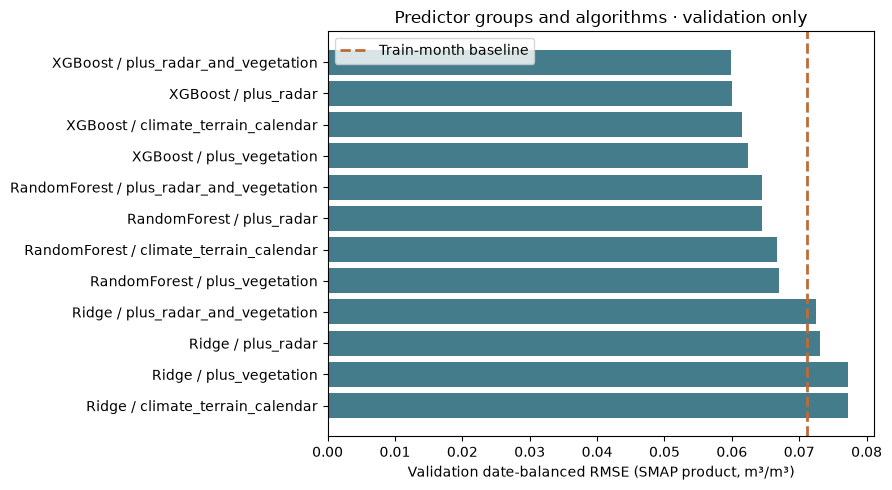

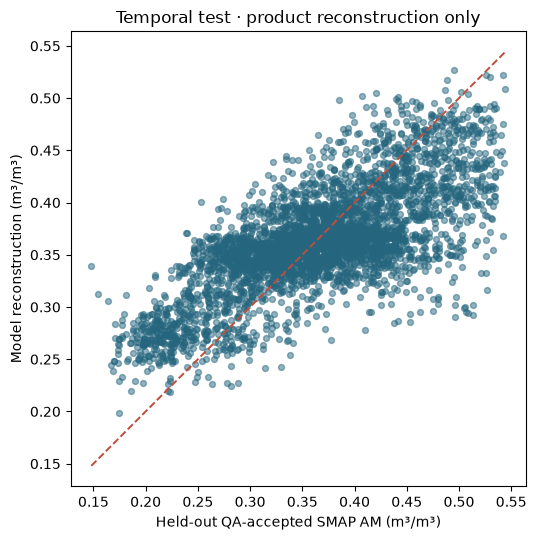

Finished Notebook 08. The independent TEST must now remain untouched.


In [8]:
FIGURES.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(9, 5))
nonbaseline = validation_scores[validation_scores.model.isin(ALGORITHMS)].copy()
nonbaseline = nonbaseline.sort_values('RMSE', ascending=False)
names = nonbaseline['model'] + ' / ' + nonbaseline['feature_group']
ax.barh(names, nonbaseline.RMSE, color='#447c8c')
ax.axvline(validation_scores[validation_scores.model.eq('calendar_month')].RMSE.iloc[0],
           color='#be6b36', linewidth=2, linestyle='--', label='Train-month baseline')
ax.set_xlabel('Validation date-balanced RMSE (SMAP product, m³/m³)')
ax.set_title('Predictor groups and algorithms · validation only')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / '08_validation_model_comparison.png', dpi=190)
plt.show()

fig, ax = plt.subplots(figsize=(5.8, 5.5))
ax.scatter(observed, pred_test, s=18, alpha=0.5, color='#25667e')
lower = min(float(np.min(observed)), float(np.min(pred_test)))
upper = max(float(np.max(observed)), float(np.max(pred_test)))
ax.plot([lower,upper], [lower,upper], '--', color='#c04d3c', linewidth=1.4)
ax.set_xlabel('Held-out QA-accepted SMAP AM (m³/m³)')
ax.set_ylabel('Model reconstruction (m³/m³)')
ax.set_title('Temporal test · product reconstruction only')
ax.set_aspect('equal', adjustable='box')
fig.tight_layout()
fig.savefig(FIGURES / '08_temporal_test_smap_scatter.png', dpi=190)
plt.show()

manifest = {
    'status': 'completed_satellite_product_reconstruction_not_ground_validated',
    'run_utc': datetime.now(timezone.utc).isoformat(),
    'source_file': str(DATA_FILE.relative_to(ROOT)),
    'source_sha256': hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
    'partition_bounds': {'train':[TRAIN_START,TRAIN_END], 'validation':[VAL_START,VAL_END],
                         'test':[TEST_START,TEST_END]},
    'selection': {'model':best_algorithm, 'features':best_group, 'basis':'validation date-weighted RMSE'},
    'xgboost_available': XGB_AVAILABLE,
    'python_sklearn': sklearn.__version__,
    'xgboost_version': xgb.__version__ if XGB_AVAILABLE else None,
    'seed': RANDOM_SEED, 'date_balance':'each calendar date total weight equal',
    'test_rmse_date_bootstrap_95_interval':rmse_bootstrap_ci,
    'validation_abs_residual_90th_percentile':validation_q90,
    'test_band_date_weighted_coverage':coverage90,
    'spatial_status':spatial_status,
    'disclaimers':['No field validation', 'SMAP posting is not independent footprint',
                   'QA-selected sites/dates only', 'No test-set early stopping']
}
(TABLES / '08_model_run_manifest.json').write_text(json.dumps(manifest, indent=2),
                                                   encoding='utf-8')
print('Finished Notebook 08. The independent TEST must now remain untouched.')
